In [1]:
# rsync -av --progress /scratch/franzihe/input/COMBLE u6030275@notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data 

# rsync -av --progress login.nird.sigma2.no:/projects/NS9600K/data/Met-No_obs/  /uio/kant/geo-metos-u1/franzihe/Documents/input/Met-No_obs

In [2]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]


if "mimi" in hostname:
    DATA_DIR = "/scratch/franzihe/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity/"

elif "augustiner" in hostname: 
    DATA_DIR = "/home/franzihe/Data/"
    FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

elif "wessel" in hostname:
    DATA_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

mimi.uio.no


## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [3]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt,radar, np, DateFormatter, datetime, cm, pd, da, IMProToo,fct)
version = IMProToo.__version__


In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
sites = ["ANX", ]#"ALOMAR"]
years = [#"2021", 
"2022"]

In [6]:
mrr_in_dict = {}
ds_dict = {}
met_no_dict = {}
ds_dict_metno = {}
for site in sites:
    for year in years:
        mrr_in_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'MRR_islas/maahn/*{}*{}*'.format(site, year))))
        met_no_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*{}*'.format(year))))
        try:
            ds_dict['{}.{}'.format(site, year)] = xr.open_mfdataset(mrr_in_dict['{}.{}'.format(site, year)], decode_times=True, )
            ds_dict_metno['{}.{}'.format(site, year)] = xr.open_mfdataset(met_no_dict['{}.{}'.format(site, year)], decode_times=True, )
            print("Reading files for {} in {}".format(site, year))
        except OSError:
            ds_dict['{}.{}'.format(site, year)] = xr.Dataset()
            ds_dict_metno['{}.{}'.format(site, year)] = xr.Dataset()
            # print("No files to open for {} in {}".format(site, year))
            continue

Reading files for ANX in 2022


In [ ]:
for key in mrr_in_dict.keys():
    # print(len(mrr_in_dict[key]))
    

    for j in range(len(mrr_in_dict[key])):
        
        
        date = mrr_in_dict[key][j][-11:-3]
        print("reading file for {}, {}...".format(site, date))
        
        figname = 'mrr_reflectivity_{}_{}.png'.format(site,date)
        file_out = "{}_{}_{}_{}.nc".format(os.path.join(OUTPUT_DATA_DIR, 'MRR_islas/bin_averaged/mrr_improtoo'), version, site, date)

        
        # Define start and end time of individual day
        day_start = datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S').strftime('%Y-%m-%d %H:%M:%S')
        # print(day_start)
        day_end = (datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S') + datetime.timedelta(hours=23, minutes=59)).strftime('%Y-%m-%d %H:%M:%S')
        _xmax = (datetime.datetime.strptime(day_end, '%Y-%m-%d %H:%M:%S') + datetime.timedelta(minutes=1,)).strftime('%Y-%m-%d %H:%M:%S')

        # select Met-No data
        _air_temp = ds_dict_metno[key]['air_temperature'].sel(time = slice(day_start, day_end))
        _wd = ds_dict_metno[key]['wind_from_direction'].sel(time = slice(day_start, day_end))
        _ws = ds_dict_metno[key]['wind_speed'].sel(time = slice(day_start, day_end))
        _pp = ds_dict_metno[key]['sum(precipitation_amount PT1H)'].sel(time = slice(day_start, day_end))

        

        # create new dataset with time resolution 1 minute
        _time = pd.date_range(day_start, periods=1440, freq="min").strftime('%Y-%m-%dT%H:%M:%S')
        dsx = xr.Dataset(data_vars=dict(
                                        air_temperature=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_direction=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_speed=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        precipitation=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        Ze=(["time","range"], da.full(shape= (len(_time),len(ds_dict[key].range)), fill_value = np.nan)),
                                        W=(["time","range"], da.full(shape= (len(_time),len(ds_dict[key].range)), fill_value = np.nan)),
                                        height=(["time","range"], da.full(shape= (len(_time),len(ds_dict[key].range)), fill_value = np.nan)),
                                        spectralWidth=(["time","range"], da.full(shape= (len(_time),len(ds_dict[key].range)), fill_value = np.nan)),),
                        coords=dict(time=_time, range=ds_dict[key].range.values))
        # assign variables and attributes to the dataset
        dsx['time'] = pd.to_datetime(dsx.time)
        dsx['air_temperature'].attrs = _air_temp.attrs
        dsx['wind_direction'].attrs = _wd.attrs
        dsx['wind_speed'].attrs = _ws.attrs
        dsx['precipitation'].attrs = _pp.attrs

        dsx['air_temperature'] = fct.arrays_same_time_res(_air_temp, dsx['air_temperature'])
        dsx['wind_direction']  = fct.arrays_same_time_res(_wd, dsx['wind_direction'])
        dsx['wind_speed']      = fct.arrays_same_time_res(_ws, dsx['wind_speed'])
        dsx['precipitation']   = fct.arrays_same_time_res(_pp, dsx['precipitation'])
        dsx['precipitation']   = dsx['precipitation'].resample(time='1H').sum('time', skipna=True, keep_attrs=True)
        dsx['precipitation']   = dsx['precipitation'].assign_attrs({'units':'mm h-1'})



        # read MRR data
        _Ze = ds_dict[key]['Ze'].sel(time = slice(day_start, day_end))
        _height = ds_dict[key]['height'].sel(time = slice(day_start, day_end))
        
        _W = (ds_dict[key]['W'].sel(time = slice(day_start, day_end)))*(-1)
        _W = _W.where(_Ze>=-20.)
        _W = _W.assign_attrs(ds_dict[key]['W'].attrs)
        
        _sWidth = ds_dict[key]['spectralWidth'].sel(time = slice(day_start, day_end))
        _sWidth = _sWidth.where(_Ze>=-20.)
        _sWidth = _sWidth.assign_attrs(ds_dict[key]['spectralWidth'].attrs)


        
        try:
                _Ze.sel(time=dsx.time[0].values).time.size
        except KeyError:
                print(KeyError)
                _Ze = _Ze
                _height = _height
                _W = _W
                _sWidth = _sWidth
        else:
                if _Ze.sel(time=dsx.time[0].values).time.size >1:
                        _l = _Ze.sel(time=dsx.time[0].values).time.size
                        _Ze = _Ze.isel(time=slice((_l-1), 1441))
                if _height.sel(time=dsx.time[0].values).time.size >1:
                        _l = _height.sel(time=dsx.time[0].values).time.size
                        _height = _height.isel(time=slice((_l-1), 1441))
                if _W.sel(time=dsx.time[0].values).time.size >1:
                        _l = _W.sel(time=dsx.time[0].values).time.size
                        _W = _W.isel(time=slice((_l-1), 1441))
                if _sWidth.sel(time=dsx.time[0].values).time.size >1:
                        _l = _sWidth.sel(time=dsx.time[0].values).time.size
                        _sWidth = _sWidth.isel(time=slice((_l-1), 1441))
        
        
        
        dsx['Ze'].attrs = _Ze.attrs
        dsx['W'].attrs = _W.attrs
        dsx['height'].attrs = _height.attrs
        dsx['spectralWidth'].attrs = _sWidth.attrs

        
        dsx['Ze']              = fct.arrays_same_time_res(_Ze, dsx['Ze'])
        dsx['W']               = fct.arrays_same_time_res(_W, dsx['W'])
        dsx['height']          = fct.arrays_same_time_res(_height, dsx['height'])
        dsx['spectralWidth']   = fct.arrays_same_time_res(_sWidth, dsx['spectralWidth'])

        # create Dataset with all variables needed
        dsx = dsx.assign_attrs({'title': 'Micro rain radar data processed with IMProToo and bin averaged',
                                'comment': ds_dict[key].attrs['comment'],
                                'institution': ds_dict[key].attrs['institution'],
                                'contact_person': ds_dict[key].attrs['contact_person'],
                                'source': ds_dict[key].attrs['source'],
                                'location': ds_dict[key].attrs['location'],
                                'history': ds_dict[key].attrs['history'],
                                'processing_date': ds_dict[key].attrs['processing_date'],
                                'reference': ds_dict[key].attrs['reference'],
                                'mrrHeader': ds_dict[key].attrs['mrrHeader']})
        
        print("writing...", file_out)
        dsx.to_netcdf(file_out)

        fct.plt_Ze_W_p_T_U(dsx, day_start, _xmax, key)
        
        # save image to png
        plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True)



In [147]:
        # create new dataset with time resolution 1 minute
        _time = pd.date_range(day_start, periods=1440, freq="min").strftime('%Y-%m-%dT%H:%M:%S')
        dsm = xr.Dataset(data_vars=dict(
                                        air_temperature=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_direction=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_speed=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        precipitation=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        Ze=(["time","range"], da.full(shape= (len(_time),len(_Ze_mean.range)), fill_value = np.nan)),
                                        W=(["time","range"], da.full(shape= (len(_time),len(_Ze_mean.range)), fill_value = np.nan)),
                                        height=(["time","range"], da.full(shape= (len(_time),len(_Ze_mean.range)), fill_value = np.nan)),
                                        spectralWidth=(["time","range"], da.full(shape= (len(_time),len(_Ze_mean.range)), fill_value = np.nan)),),
                        coords=dict(time=_time, range=_Ze_mean.range.values))
        # assign variables and attributes to the dataset
        dsm['time'] = pd.to_datetime(dsm.time)
        dsm['air_temperature'].attrs = _air_temp.attrs
        dsm['wind_direction'].attrs = _wd.attrs
        dsm['wind_speed'].attrs = _ws.attrs
        dsm['precipitation'].attrs = _pp.attrs

        dsm['air_temperature'] = fct.arrays_same_time_res(_air_temp, dsm['air_temperature'])
        dsm['wind_direction']  = fct.arrays_same_time_res(_wd, dsm['wind_direction'])
        dsm['wind_speed']      = fct.arrays_same_time_res(_ws, dsm['wind_speed'])
        dsm['precipitation']   = fct.arrays_same_time_res(_pp, dsm['precipitation'])
        dsm['precipitation']   = dsm['precipitation'].resample(time='1H').sum('time', skipna=True, keep_attrs=True)
        dsm['precipitation']   = dsm['precipitation'].assign_attrs({'units':'mm h-1'})



In [166]:
        ## Average MRR variables in range bins
        # Radar equivalent reflectivity ($Ze$) in dBz is transformed to MRR radar reflectivity ($Z$) 
        # in $mm^6 m^{-3}$ by the following relationship:
        # # $$Ze = 10log_{10} (\frac{Z}{mm^6 m^{-3}})$$
        # # $$Z = 10^{Ze/10} mm^6 m^{-3}$$
        # # Once we know $Z$ it is possible to average over range sizes. The assumption is that the 4th 
        # range represents the bin between 300 and 400m and so on. Reflectivity, Doppler velocity, and height will 
        # be averaged in the bins (4,5), (6,7), (8,9), ... (26,27), (28,29), (30,31)
        

        _Ze_mean = xr.DataArray(data=da.full(shape = (len(_Ze.time),len(_Ze.range[1:-1][::2])), fill_value=np.nan), coords ={'time':_Ze.time.values, 'range':_Ze.range[1:-1][::2]})
        _W_mean = xr.DataArray(data=da.full(shape = (len(_W.time),len(_W.range[1:-1][::2])), fill_value=np.nan), coords={'time':_W.time.values, 'range':_W.range[1:-1][::2]})
        _height_mean = xr.DataArray(data=da.full(shape = (len(_height.time),len(_height.range[1:-1][::2])),fill_value=np.nan),coords={'time':_height.time.values, 'range':_height.range[1:-1][::2]})
        _sWidth_mean = xr.DataArray(data=da.full(shape = (len(_sWidth.time),len(_sWidth.range[1:-1][::2])),fill_value=np.nan),coords={'time':_sWidth.time.values, 'range':_sWidth.range[1:-1][::2]})
        for i, k in zip(_Ze.range[1:-1][::2].values, range(len(_Ze.range[1:-1][::2]))):
                _Z = 10**(_Ze.sel(range=slice(i, (i+1)))/10)
                _Z_mean = _Z.mean('range', skipna=True, keep_attrs=True)
                _Ze_mean[:, k] = 10*np.log10(_Z_mean)

                _W_mean[:,k] = _W.sel(range=slice(i, (i+1))).mean('range', skipna=True, keep_attrs=True)
                _height_mean[:,k] = _height.sel(range=slice(i, (i+1))).mean('range', skipna=True, keep_attrs=True)
                _sWidth_mean[:,k] = _sWidth.sel(range=slice(i, (i+1))).mean('range', skipna=True, keep_attrs=True)


        dsm['Ze'].attrs = _Ze.attrs
        dsm['W'].attrs = _W.attrs
        dsm['height'].attrs = _height.attrs
        dsm['spectralWidth'].attrs = _sWidth.attrs

        dsm['Ze']              = fct.arrays_same_time_res(_Ze_mean, dsm['Ze'])
        dsm['W']               = fct.arrays_same_time_res(_W_mean, dsm['W'])
        dsm['height']          = fct.arrays_same_time_res(_height_mean, dsm['height'])
        dsm['spectralWidth']   = fct.arrays_same_time_res(_sWidth_mean, dsm['spectralWidth'])
 

In [167]:
_Ze.attrs

{'description': 'reflectivity of the most significant peak', 'units': 'dBz'}

In [168]:
dsm['Ze'].attrs

{'description': 'reflectivity of the most significant peak', 'units': 'dBz'}

RecursionError: maximum recursion depth exceeded while calling a Python object

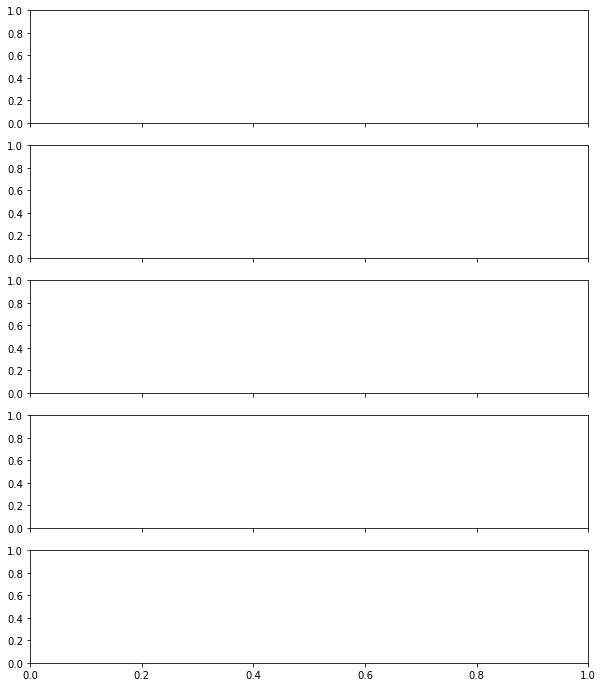

In [169]:
fct.plt_Ze_W_p_T_U(dsm, day_start, _xmax, key)

In [ ]:
# rsync -a --progress /home/franzihe/Documents/Figures/mrr_reflectivity notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/u6030275/public_html/Figures

In [ ]:
# rsync -a --progress login.nird.sigma2.no:/projects/NS9600K/sldam/timelapses_islas2022 /home/franzihe/Documents/Figures